<a href="https://colab.research.google.com/github/rehim2009book-ui/fairloan/blob/main/fairloan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:
!pip install -q ucimlrepo

In [17]:
# ===================== CELL 1: load data and make it readable =====================
# What it does: downloads the 1,000 loan applicants, renames the cryptic columns, turns codes into words.
import pandas as pd, numpy as np
from ucimlrepo import fetch_ucirepo

raw = fetch_ucirepo(id=144)
X = raw.data.features.copy()
y_raw = raw.data.targets["class"]          # 1 = good (paid back), 2 = bad

names = {
 "Attribute1":"checking","Attribute2":"duration_months","Attribute3":"credit_history","Attribute4":"purpose",
 "Attribute5":"amount","Attribute6":"savings","Attribute7":"employment","Attribute8":"installment_rate",
 "Attribute9":"personal_status","Attribute10":"other_debtors","Attribute11":"residence_years","Attribute12":"property",
 "Attribute13":"age","Attribute14":"other_plans","Attribute15":"housing","Attribute16":"existing_credits",
 "Attribute17":"job","Attribute18":"people_liable","Attribute19":"telephone","Attribute20":"foreign_worker"}
X = X.rename(columns=names)

codes = {
 "checking":{"A11":"<0","A12":"0-200","A13":">=200","A14":"none"},
 "credit_history":{"A30":"no credits","A31":"all paid","A32":"paying ok","A33":"delayed past","A34":"critical"},
 "purpose":{"A40":"new car","A41":"used car","A42":"furniture","A43":"tv/radio","A44":"appliances","A45":"repairs",
            "A46":"education","A47":"vacation","A48":"retraining","A49":"business","A410":"other"},
 "savings":{"A61":"<100","A62":"100-500","A63":"500-1000","A64":">=1000","A65":"none/unknown"},
 "employment":{"A71":"unemployed","A72":"<1yr","A73":"1-4yr","A74":"4-7yr","A75":">=7yr"},
 "personal_status":{"A91":"A91","A92":"A92","A93":"A93","A94":"A94","A95":"A95"},   # sex NOT recoverable - keep codes
 "other_debtors":{"A101":"none","A102":"co-applicant","A103":"guarantor"},
 "property":{"A121":"real estate","A122":"savings/insurance","A123":"car/other","A124":"none"},
 "other_plans":{"A141":"bank","A142":"stores","A143":"none"},
 "housing":{"A151":"rent","A152":"own","A153":"free"},
 "job":{"A171":"unskilled non-resident","A172":"unskilled","A173":"skilled","A174":"management"},
 "telephone":{"A191":"no","A192":"yes"},
 "foreign_worker":{"A201":"yes","A202":"no"},   # known to be inverted in this release - we do not use it
}
for col, m in codes.items():
    X[col] = X[col].map(m).fillna(X[col])

df = X.copy()
df["approve"] = (y_raw == 1).astype(int)            # 1 = good risk = approve
df["young"] = (df["age"] < 25).astype(int)           # the group we audit
print(df.shape)
df.head()

(1000, 22)


,checking,duration_months,credit_history,purpose,amount,savings,employment,installment_rate,personal_status,other_debtors,...,age,other_plans,housing,existing_credits,job,people_liable,telephone,foreign_worker,approve,young
0,<0,6,critical,tv/radio,1169,none/unknown,>=7yr,4,A93,none,...,67,none,own,2,skilled,1,yes,yes,1,0
1,0-200,48,paying ok,tv/radio,5951,<100,1-4yr,2,A92,none,...,22,none,own,1,skilled,1,no,yes,0,1
2,none,12,critical,education,2096,<100,4-7yr,2,A93,none,...,49,none,own,1,unskilled,2,no,yes,1,0
3,<0,42,paying ok,furniture,7882,<100,4-7yr,2,A93,guarantor,...,45,none,free,1,skilled,2,no,yes,1,0
4,<0,24,delayed past,new car,4870,<100,1-4yr,3,A93,none,...,53,none,free,2,skilled,2,no,yes,0,0


In [18]:
# ===================== CELL 2: look at the data =====================
# What it does: counts people, approvals, and how many are under 25.
print("Applicants:", len(df))
print("Good risk (approve):", df.approve.sum(), "=", f"{df.approve.mean():.0%}")
print("Under 25:", df.young.sum(), " | 25 and over:", (1-df.young).sum())
print("\nReal repayment rate by age group:")
print(df.groupby(df.young.map({1:"under 25",0:"25+"}))["approve"].mean().round(3))
print("\nHousing by age group (share renting):")
print(df.groupby(df.young.map({1:"under 25",0:"25+"}))["housing"].apply(lambda s:(s=="rent").mean()).round(2))

Applicants: 1000
Good risk (approve): 700 = 70%
Under 25: 149  | 25 and over: 851

Real repayment rate by age group:
young
25+         0.719
under 25    0.591
Name: approve, dtype: float64

Housing by age group (share renting):
young
25+         0.13
under 25    0.46
Name: housing, dtype: float64


In [19]:
# ===================== CELL 3: split + baseline + cost =====================
# What it does: holds back 20% for testing. Baseline = approve everyone. Cost = official 5:1 rule.
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score

FEATURES = [c for c in df.columns if c not in ["approve","young","foreign_worker","personal_status"]]
X_train, X_test, y_train, y_test = train_test_split(
    df[FEATURES], df["approve"], test_size=0.2, stratify=df["approve"], random_state=42)
young_test = (X_test["age"] < 25).astype(int)

def cost(y_true, y_pred):
    """Bank's money lost. Approving a bad risk costs 5, rejecting a good one costs 1."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    bad_approved = ((y_true==0)&(y_pred==1)).sum()
    good_rejected = ((y_true==1)&(y_pred==0)).sum()
    return 5*bad_approved + 1*good_rejected

def report(name, y_true, y_pred):
    print(f"{name}")
    print(f"  accuracy          {accuracy_score(y_true,y_pred):.1%}")
    print(f"  bad-risk recall   {recall_score(1-np.asarray(y_true),1-np.asarray(y_pred)):.1%}   (share of bad risks we caught)")
    print(f"  cost (5:1 rule)   {cost(y_true,y_pred)}   (lower is better)")

baseline = np.ones(len(y_test), dtype=int)
report("Baseline: approve everyone", y_test, baseline)

Baseline: approve everyone
  accuracy          70.0%
  bad-risk recall   0.0%   (share of bad risks we caught)
  cost (5:1 rule)   300   (lower is better)


In [20]:
# ===================== CELL 4: train two models, pick one =====================
# What it does: logistic regression + random forest. We keep whichever loses less money.
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

num_cols = ["duration_months","amount","installment_rate","residence_years","age","existing_credits","people_liable"]
cat_cols = [c for c in FEATURES if c not in num_cols]

def make_pipe(model, features=FEATURES):
    nums = [c for c in num_cols if c in features]; cats = [c for c in cat_cols if c in features]
    pre = ColumnTransformer([("num", StandardScaler(), nums),
                             ("cat", OneHotEncoder(handle_unknown="ignore"), cats)])
    return Pipeline([("pre", pre), ("model", model)])

lr = make_pipe(LogisticRegression(max_iter=2000, class_weight="balanced")).fit(X_train, y_train)
rf = make_pipe(RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced")).fit(X_train, y_train)

report("\nLogistic regression", y_test, lr.predict(X_test))
report("\nRandom forest",       y_test, rf.predict(X_test))

model = lr if cost(y_test, lr.predict(X_test)) <= cost(y_test, rf.predict(X_test)) else rf
print("\nWe keep:", "logistic regression" if model is lr else "random forest")


Logistic regression
  accuracy          67.0%
  bad-risk recall   68.3%   (share of bad risks we caught)
  cost (5:1 rule)   142   (lower is better)

Random forest
  accuracy          71.0%
  bad-risk recall   35.0%   (share of bad risks we caught)
  cost (5:1 rule)   214   (lower is better)

We keep: logistic regression


In [21]:
# ===================== CELL 5: Audit I - does it approve young people less? =====================
# What it does: approval rate for under-25 vs 25+, on the test set. The gap is our headline number.
pred = model.predict(X_test)
tab = pd.DataFrame({"approved": pred, "group": young_test.map({1:"under 25",0:"25+"})})
rates = tab.groupby("group")["approved"].agg(["mean","count"]).rename(columns={"mean":"approval_rate","count":"people"})
print(rates.round(3))
gap = rates.loc["25+","approval_rate"] - rates.loc["under 25","approval_rate"]
print(f"\nGap: 25+ approved {gap:.1%} more often than under-25s.")
print("(Note: the real repayment rates also differ by age - see cell 2. The question is whether the model's gap is bigger than the data justifies, and what drives it. Cells 6-7 answer that.)")

          approval_rate  people
group                          
25+               0.581     172
under 25          0.429      28

Gap: 25+ approved 15.3% more often than under-25s.
(Note: the real repayment rates also differ by age - see cell 2. The question is whether the model's gap is bigger than the data justifies, and what drives it. Cells 6-7 answer that.)


In [22]:
# ===================== CELL 6: Audit II - delete age. Is it still unfair? And can the model guess age anyway? =====================
# What it does: (a) retrain WITHOUT the age column, measure the gap again (on the test set AND on all 1,000 via cross-validation).
#               (b) "attacker": a model that tries to guess who is under 25 from the other columns.
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_auc_score

FEATURES_NOAGE = [c for c in FEATURES if c != "age"]
model_noage = make_pipe(LogisticRegression(max_iter=2000, class_weight="balanced"), FEATURES_NOAGE).fit(X_train[FEATURES_NOAGE], y_train)

def approval_gap(pred, young_flag):
    r = pd.Series(pred).groupby(np.asarray(young_flag)).mean()
    return r[0] - r[1]            # 25+ rate minus under-25 rate

pred_noage = model_noage.predict(X_test[FEATURES_NOAGE])
gap_noage = approval_gap(pred_noage, young_test)
print("TEST SET (200 people, only 28 under 25 - noisy):")
print(f"  gap WITH age column:    {gap:.1%}")
print(f"  gap WITHOUT age column: {gap_noage:.1%}")
print(f"  cost without age: {cost(y_test, pred_noage)}  (with age: {cost(y_test, pred)})")

# steadier: predict every one of the 1,000 people with cross-validation (each person predicted by a model that never saw them)
cv_with    = cross_val_predict(make_pipe(LogisticRegression(max_iter=2000, class_weight="balanced")), df[FEATURES], df["approve"], cv=5)
cv_without = cross_val_predict(make_pipe(LogisticRegression(max_iter=2000, class_weight="balanced"), FEATURES_NOAGE), df[FEATURES_NOAGE], df["approve"], cv=5)
gap_cv_with, gap_cv_without = approval_gap(cv_with, df["young"]), approval_gap(cv_without, df["young"])
print("\nALL 1,000 PEOPLE (149 under 25, cross-validated):")
print(f"  gap WITH age column:    {gap_cv_with:.1%}")
print(f"  gap WITHOUT age column: {gap_cv_without:.1%}")
if gap_cv_without > 0.5*gap_cv_with:
    print("  -> deleting age removes less than half the gap. The model finds age another way.")
elif gap_cv_without > 0.02:
    print("  -> deleting age shrinks the gap, but a real gap remains. The model finds age another way.")
else:
    print("  -> deleting age closes most of the gap in this data.")

# (b) attacker: guess 'young' from everything except age
attacker = make_pipe(LogisticRegression(max_iter=2000, class_weight="balanced"), FEATURES_NOAGE)
guess = cross_val_predict(attacker, df[FEATURES_NOAGE], df["young"], cv=5, method="predict_proba")[:,1]
auc = roc_auc_score(df["young"], guess)
print(f"\nAttacker AUC for guessing 'under 25' without seeing age: {auc:.2f}   (0.50 = coin flip, 1.00 = perfect)")

attacker.fit(df[FEATURES_NOAGE], df["young"])
feat_names = attacker.named_steps["pre"].get_feature_names_out()
coefs = pd.Series(attacker.named_steps["model"].coef_[0], index=feat_names)
print("\nTop clues that someone is YOUNG:");  print(coefs.sort_values(ascending=False).head(6).round(2))
print("\nTop clues that someone is OLDER:"); print(coefs.sort_values().head(6).round(2))

TEST SET (200 people, only 28 under 25 - noisy):
  gap WITH age column:    15.3%
  gap WITHOUT age column: 7.0%
  cost without age: 148  (with age: 142)

ALL 1,000 PEOPLE (149 under 25, cross-validated):
  gap WITH age column:    17.4%
  gap WITHOUT age column: 13.8%
  -> deleting age removes less than half the gap. The model finds age another way.

Attacker AUC for guessing 'under 25' without seeing age: 0.78   (0.50 = coin flip, 1.00 = perfect)

Top clues that someone is YOUNG:
cat__housing_rent          1.20
cat__purpose_repairs       0.83
cat__job_skilled           0.57
cat__employment_<1yr       0.56
cat__purpose_appliances    0.46
cat__checking_<0           0.43
dtype: float64

Top clues that someone is OLDER:
cat__job_management     -1.14
cat__employment_>=7yr   -1.03
cat__purpose_business   -0.76
cat__housing_free       -0.73
cat__purpose_other      -0.65
cat__checking_none      -0.56
dtype: float64


        feature                 twins             kind flips (everyone) flips (real under-25s)
       checking            <0 vs none            money              50%                    57%
        savings        <100 vs >=1000            money              29%                    34%
       property   none vs real estate stand-in for age              16%                    15%
        housing           rent vs own stand-in for age              13%                    14%
     employment         <1yr vs >=7yr stand-in for age               8%                     9%
      telephone             no vs yes stand-in for age               7%                     7%
            job skilled vs management stand-in for age               7%                     6%
residence_years                1 vs 4 stand-in for age               0%                     0%


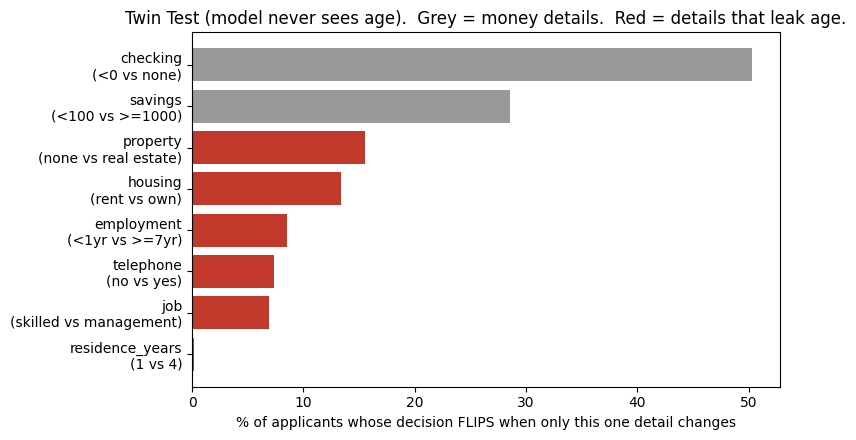


Strongest age stand-in: property - flips the decision for 16% of applicants, though the model was never told anyone's age.

Leyla (rents):          approve chance 47%  -> REJECTED
Her twin (owns a home): approve chance 61%  -> APPROVED
Everything else about them is identical. The model was never told their age.

How many real under-25 renters are rejected but would be approved as home-owners: 7 of 69


In [23]:
# ===================== CELL 7: Audit III - the Twin Test =====================
# What it does: for each detail, every applicant gets an identical twin that differs ONLY in that detail
# (young-typical value vs older-typical value). We count how often the age-free model changes its answer.
# Grey = money details a bank is allowed to care about. Red = details that mostly just leak age.
import matplotlib.pyplot as plt

# (feature, young-typical value, older-typical value, kind)  - directions taken from the attacker's clues above
TWIN_PAIRS = [
    ("housing",         "rent",   "own",         "stand-in for age"),
    ("employment",      "<1yr",   ">=7yr",       "stand-in for age"),
    ("job",             "skilled","management",  "stand-in for age"),
    ("telephone",       "no",     "yes",         "stand-in for age"),
    ("property",        "none",   "real estate", "stand-in for age"),
    ("residence_years", 1,        4,             "stand-in for age"),
    ("savings",         "<100",   ">=1000",      "money"),
    ("checking",        "<0",     "none",        "money"),
]

def twin_test(model, data, feature, young_val, old_val):
    a = data.copy(); a[feature] = young_val
    b = data.copy(); b[feature] = old_val
    return (model.predict(a) != model.predict(b))        # True where the decision flips

rows = []
is_young = df["young"].values.astype(bool)
for f, yv, ov, kind in TWIN_PAIRS:
    flips = twin_test(model_noage, df[FEATURES_NOAGE], f, yv, ov)
    rows.append({"feature": f, "twins": f"{yv} vs {ov}", "kind": kind,
                 "flips (everyone)": flips.mean(), "flips (real under-25s)": flips[is_young].mean()})
twins = pd.DataFrame(rows).sort_values("flips (everyone)", ascending=False)
print(twins.to_string(index=False, formatters={"flips (everyone)":"{:.0%}".format, "flips (real under-25s)":"{:.0%}".format}))

colors = twins["kind"].map({"money":"#999999", "stand-in for age":"#c0392b"})
plt.figure(figsize=(8,4.5))
plt.barh(twins["feature"] + "\n(" + twins["twins"] + ")", twins["flips (everyone)"]*100, color=colors)
plt.gca().invert_yaxis()
plt.xlabel("% of applicants whose decision FLIPS when only this one detail changes")
plt.title("Twin Test (model never sees age).  Grey = money details.  Red = details that leak age.")
plt.tight_layout(); plt.show()

standin_total = twins.loc[twins.kind=="stand-in for age","flips (everyone)"].max()
print(f"\nStrongest age stand-in: {twins.loc[twins.kind=='stand-in for age'].iloc[0]['feature']} "
      f"- flips the decision for {standin_total:.0%} of applicants, though the model was never told anyone's age.")

# One concrete twin for the demo: a real under-25 renter whose decision flips when only 'housing' changes
cands = df[(df.age < 25) & (df.housing == "rent")][FEATURES_NOAGE]
cands_twin = cands.copy(); cands_twin["housing"] = "own"
flipped = (model_noage.predict(cands) == 0) & (model_noage.predict(cands_twin) == 1)
leyla = cands[flipped].iloc[[0]] if flipped.any() else cands.iloc[[0]]
twin  = leyla.copy(); twin["housing"] = "own"
p1 = model_noage.predict_proba(leyla)[0,1]; p2 = model_noage.predict_proba(twin)[0,1]
print(f"\nLeyla (rents):          approve chance {p1:.0%}  -> {'APPROVED' if p1>=0.5 else 'REJECTED'}")
print(f"Her twin (owns a home): approve chance {p2:.0%}  -> {'APPROVED' if p2>=0.5 else 'REJECTED'}")
print("Everything else about them is identical. The model was never told their age.")
print(f"\nHow many real under-25 renters are rejected but would be approved as home-owners: {flipped.sum()} of {len(cands)}")

In [24]:
# ===================== CELL 7b: the fair question - among people who really PAID BACK, who got wrongly rejected? =====================
# What it does: young people in this data repay a bit less often, so some gap is expected.
# The fair test is: look ONLY at people who did pay back. Does the model wrongly reject the young ones more often?
good = df["approve"].values == 1
print(f"People who really paid back: {(good & is_young).sum()} under 25, {(good & ~is_young).sum()} aged 25+\n")
for label, p in [("model WITH age", cv_with), ("model WITHOUT age", cv_without)]:
    wrong_young = (p[good & is_young] == 0).mean()
    wrong_old   = (p[good & ~is_young] == 0).mean()
    print(f"{label}:")
    print(f"   good payers wrongly rejected, under 25: {wrong_young:.1%}")
    print(f"   good payers wrongly rejected, 25+:      {wrong_old:.1%}")
    print(f"   -> a young good payer is {wrong_young/wrong_old:.1f}x as likely to be wrongly rejected\n")
print(f"For comparison, real repayment rates: under 25 {df.approve[is_young].mean():.1%}, 25+ {df.approve[~is_young].mean():.1%}")

People who really paid back: 88 under 25, 612 aged 25+

model WITH age:
   good payers wrongly rejected, under 25: 39.8%
   good payers wrongly rejected, 25+:      25.8%
   -> a young good payer is 1.5x as likely to be wrongly rejected

model WITHOUT age:
   good payers wrongly rejected, under 25: 37.5%
   good payers wrongly rejected, 25+:      26.8%
   -> a young good payer is 1.4x as likely to be wrongly rejected

For comparison, real repayment rates: under 25 59.1%, 25+ 71.9%


In [25]:
!pip install -q -U google-genai

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.2 which is incompatible.
google-adk 2.7.1 requires google-genai<3,>=2.12.1, but you have google-genai 3.3.0 which is incompatible.


In [27]:
# ===================== CELL 10: the explainer - why did I get this answer? =====================
# Before this cell, run a tiny cell with:   !pip install -q -U google-genai
# What it does: (a) finds the 3 details that pushed THIS person's decision the most,
#               (b) asks Gemini to turn them into 3 plain sentences,
#               (c) saves every answer to explanations.json so the notebook also runs with no API key.
import json, os

USE_API = True                       # set to False to use only saved answers (what judges will get)
CACHE_FILE = "explanations.json"
GEMINI_MODELS = ["gemini-3.5-flash-lite", "gemini-3.1-flash-lite", "gemini-2.5-flash"]   # tried in this order

PLAIN = {"checking":"checking account balance", "duration_months":"loan length (months)", "credit_history":"credit history",
         "purpose":"loan purpose", "amount":"loan amount", "savings":"savings", "employment":"time in current job",
         "installment_rate":"share of income going to repayments", "other_debtors":"co-applicant or guarantor",
         "residence_years":"years at current address", "property":"property owned", "other_plans":"other payment plans",
         "housing":"housing (rent / own / free)", "existing_credits":"number of existing loans", "job":"job type",
         "people_liable":"number of dependants", "telephone":"registered telephone"}

# ---- (a) the model's real reasons ----
_pre, _clf = model_noage.named_steps["pre"], model_noage.named_steps["model"]
_names = list(_pre.get_feature_names_out())
_avg = np.asarray(_pre.transform(X_train[FEATURES_NOAGE]).mean(axis=0)).ravel() * _clf.coef_[0]   # the average applicant

def _owner(col_name):
    """Which original column does this model input belong to?"""
    if col_name.startswith("num__"): return col_name[5:]
    for c in sorted(FEATURES_NOAGE, key=len, reverse=True):
        if col_name.startswith(f"cat__{c}_"): return c
    return col_name

def top_drivers(person, k=3):
    """Returns the decision, the approve chance, and the k details that pushed hardest toward that decision."""
    xt = _pre.transform(person[FEATURES_NOAGE])
    xt = np.asarray(xt.todense()).ravel() if hasattr(xt, "todense") else np.asarray(xt).ravel()
    push = pd.Series(xt * _clf.coef_[0] - _avg, index=[_owner(n) for n in _names]).groupby(level=0).sum()
    prob = model_noage.predict_proba(person[FEATURES_NOAGE])[0, 1]
    approved = prob >= 0.5
    ranked = push.sort_values(ascending=not approved)          # rejected -> most negative first
    drivers = [{"feature": f, "plain": PLAIN.get(f, f), "value": str(person.iloc[0][f]),
                "effect": "helped" if v > 0 else "hurt", "strength": round(float(v), 2)}
               for f, v in ranked.head(k).items()]
    return approved, prob, drivers

# ---- (b) Gemini writes it in plain words ----
def build_prompt(approved, drivers):
    lines = "\n".join(f"- {d['plain']}: {d['value']} ({d['effect']} the application)" for d in drivers)
    return (f"A bank's computer model {'APPROVED' if approved else 'REJECTED'} a loan application.\n"
            f"These are the ONLY reasons the model used, strongest first:\n{lines}\n\n"
            "Write exactly 3 short sentences to the applicant, in plain everyday English a 15-year-old understands.\n"
            "Rules: use ONLY the reasons listed above. Do not add any other reason. Do not mention age, sex or nationality. "
            "Do not promise anything. No greeting, no sign-off.")

def template_text(approved, drivers):
    parts = ", ".join(f"{d['plain']} ({d['value']})" for d in drivers)
    return f"[template, no AI] Your application was {'approved' if approved else 'rejected'}. The details that mattered most were: {parts}."

_client = None
def ask_gemini(prompt):
    """Returns (text, model_name) or (None, None) if the API is not available."""
    global _client
    if not USE_API: return None, None
    try:
        from google import genai
        if _client is None:
            try:
                from google.colab import userdata
                key = userdata.get("GEMINI_API_KEY")
            except Exception:
                key = os.environ.get("GEMINI_API_KEY")
            if not key: print("No GEMINI_API_KEY found - using saved answers / template."); return None, None
            _client = genai.Client(api_key=key)
        for m in list(GEMINI_MODELS):
            try:
                text = _client.models.generate_content(model=m, contents=prompt).text.strip()
                GEMINI_MODELS.remove(m); GEMINI_MODELS.insert(0, m)      # remember the one that works
                return text, m
            except Exception as e:
                print(f"  ({m} failed: {str(e)[:80]})")
    except Exception as e:
        print("Gemini not available:", str(e)[:100])
    return None, None

# ---- (c) cache ----
cache = json.load(open(CACHE_FILE)) if os.path.exists(CACHE_FILE) else {}

def explain(person_id):
    """person_id = row number in df. Returns a dict with decision, drivers and the explanation text."""
    key = str(person_id)
    if key in cache: return cache[key]
    person = df.loc[[person_id]]
    approved, prob, drivers = top_drivers(person)
    text, used = ask_gemini(build_prompt(approved, drivers))
    out = {"decision": "APPROVED" if approved else "REJECTED", "approve_chance": round(float(prob), 2),
           "drivers": drivers, "text": text or template_text(approved, drivers), "written_by": used or "template"}
    if text:                                   # only save real AI answers
        cache[key] = out
        json.dump(cache, open(CACHE_FILE, "w"), indent=1)
    return out

# ---- try it on Leyla and on one approved person ----
approved_id = int(df.index[model_noage.predict(df[FEATURES_NOAGE]) == 1][0])
for pid in [int(leyla.index[0]), approved_id]:
    r = explain(pid)
    print(f"Applicant #{pid}: {r['decision']} (approve chance {r['approve_chance']:.0%})   [written by: {r['written_by']}]")
    for d in r["drivers"]:
        print(f"   model's real reason: {d['plain']} = {d['value']}  ({d['effect']}, strength {d['strength']})")
    print("   " + r["text"] + "\n")
print(f"Saved answers in {CACHE_FILE}: {len(cache)}")

Applicant #93: REJECTED (approve chance 47%)   [written by: gemini-3.5-flash-lite]
   model's real reason: property owned = none  (hurt, strength -0.47)
   model's real reason: housing (rent / own / free) = rent  (hurt, strength -0.47)
   model's real reason: co-applicant or guarantor = co-applicant  (hurt, strength -0.28)
   We had to turn down your loan application because you do not own any property. Having a rental home also hurt your chances. Finally, applying with a co-applicant worked against you in our system.

Applicant #0: APPROVED (approve chance 87%)   [written by: gemini-3.5-flash-lite]
   model's real reason: credit history = critical  (helped, strength 0.62)
   model's real reason: savings = none/unknown  (helped, strength 0.57)
   model's real reason: loan length (months) = 6  (helped, strength 0.43)
   Your credit history helped your application the most. Your savings status also helped your application. Finally, your choice of a 6-month loan length helped your applica